# Integrative Project

## US015 - "Statistical analysis of the average annual profit of a user-specified railway station."

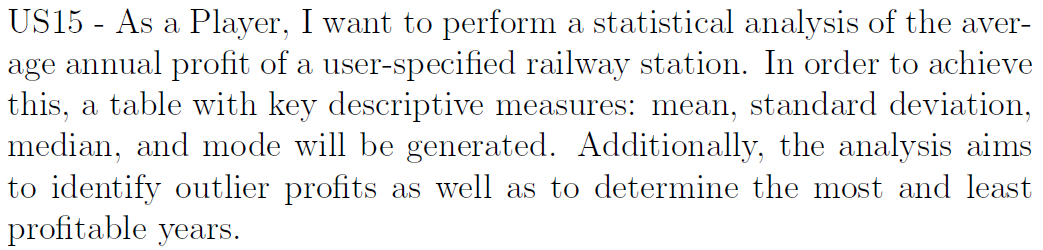

## *User Story Details:*
As a Player, I want to perform a statistical analysis of the average annual profit of a user-specified railway station. In order to achieve this, a table with key descriptive measures: mean, standard deviation, median, and mode will be generated. Additionally, the analysis aims to identify outlier profits as well as to determine the most and least profitable years.

### *Theoretical Explanation*

### What is a 'Mean'?
In mathematics, the mean, also known as arithmetic mean (or average), is calculated by summing all the numbers in a set and then dividing by the total number of values in that set. This results in a single value that represents the central tendency of the data.

Formula: Mean (μ) = Σx / n


### What is a standard deviation?
In mathematics and statistics, standard deviation is a measure of the dispersion or spread of a dataset. It quantifies how much individual data points deviate from the mean (average) value of the dataset. A low standard deviation indicates data points are clustered tightly around the mean, while a high standard deviation suggests the data is more spread out.

Formula: Standard Deviation (σ) = √(Σ(x - μ)² / (n-1))

### What is a 'Median'?
In mathematics, the median is the middle value in a sorted list of numbers. It represents the point where half of the values are below and half are above. For a set with an odd number of values, the median is simply the middle number. For a set with an even number of values, it's the average of the two middle numbers.

Formula: Median = middle value when data is sorted


### What is a 'Mode'?
The mode is the most common number that appears in your set of data. To find the mode count how often each number appears and the number that appears the most times is the mode.

### What is an 'Outlier'?
In mathematics, an outlier is a data point that significantly deviates from the rest of the data points in a set. It can be either much larger or much smaller than the other values, essentially lying outside the typical pattern of the distribution.

Formula: Q1 = 25th percentile, Q3 = 75th percentile
Formula: IQR = Q3 - Q1
Formula: Lower bound = Q1 - 1.5 × IQR
Formula: Upper bound = Q3 + 1.5 × IQR


In [ ]:
import pandas as pd
import numpy as np

# Load data
df = pd.read_csv('Stations_Data.csv', sep=';')

# Display available stations and cargo types for user selection
print("="*60)
print("RAILWAY STATION PROFIT ANALYSIS SYSTEM")
print("="*60)

# Show available stations
available_stations = df['Station'].unique()
print(f"\nAvailable Stations ({len(available_stations)}):")
print("-" * 40)
for i, station in enumerate(sorted(available_stations), 1):
    print(f"{i:2d}. {station}")

# Show available cargo types from the dataset
cargo_types = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle']
transport_types = ['Passengers', 'Mail']
print(f"\nAvailable Cargo Types ({len(cargo_types)}):")
print("-" * 40)
for i, cargo in enumerate(cargo_types, 1):
    print(f"{i:2d}. {cargo}")

print(f"\nOther Transport Categories ({len(transport_types)}):")
print("-" * 40)
for i, transport in enumerate(transport_types, 1):
    print(f"{i:2d}. {transport}")

print("\n" + "="*60)

# Organize the document info in two columns
num_cols = ['Revenues', 'Expenses']

# Convert values to either string or NaN if they're not numeric
# Formula: Replace comma decimal separators with dots for proper numeric conversion
for col in num_cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',','.',regex=False), errors='coerce')

# Calculate the profit by calculating the difference between the revenues and expenses
# Formula: Profit = Revenues - Expenses
df['Profit'] = df['Revenues'] - df['Expenses']

# Group by station and year and calculate the sum for each station in each year
# This aggregates monthly/quarterly data into annual totals
annual_profit = (df.groupby(['Station', 'Year'], as_index=False)['Profit'].sum())

# Input - station selection
station = input("Insert the station's name: ").strip()

print("="*60)

# Show the profit for that station alone
station_data = annual_profit[annual_profit['Station'] == station]

# Check if data was found
if station_data.empty:
    print(f"No data found for station '{station}'.")
else:
    # If it is, it creates a column for profits and another for the years of the chosen station
    profits = station_data['Profit']
    years = station_data['Year']

    # Calculate descriptive statistics
    # Formula: Mean (μ) = Σx / n
    mean = profits.mean()

    # Formula: Standard Deviation (σ) = √(Σ(x - μ)² / (n-1))
    std = profits.std()

    # Formula: Median = middle value when data is sorted
    median = profits.median()

    # Mode can return multiple values if they're repeated
    # Mode = most frequently occurring value(s)
    mode = profits.mode().iloc[0] if not profits.mode().empty else None

    print(f"\nDescriptive measures for station: '{station}':")
    print(f"Mean: {mean:.2f}")
    print(f"Standard deviation: {std:.2f}")
    print(f"Median: {median:.2f}")
    print(f"Mode: {mode:.2f}")

    # Find outliers using IQR (Interquartile Range) method
    # Formula: Q1 = 25th percentile, Q3 = 75th percentile
    Q1 = profits.quantile(0.25)  # 1st quartile
    Q3 = profits.quantile(0.75)  # 3rd quartile

    # Formula: IQR = Q3 - Q1
    IQR = Q3 - Q1  # Calculate the range between quartiles

    # Formula: Lower bound = Q1 - 1.5 × IQR
    lower = Q1 - 1.5 * IQR  # Calculate the inferior limit

    # Formula: Upper bound = Q3 + 1.5 × IQR
    upper = Q3 + 1.5 * IQR  # Calculate the superior limit

    # Only keep the lines outside the lower and upper limits (outliers)
    outliers = station_data[(station_data['Profit'] < lower) | (station_data['Profit'] > upper)]

    print(f"\nFound outliers ({len(outliers)}):")
    if not outliers.empty:
        # Convert to string for display
        print(outliers[['Year', 'Profit']].to_string(index=False))
    else:
        print("No outliers found.")

    # Most and least profitable years
    # Calculate the biggest and lowest index
    max_row = station_data.loc[profits.idxmax()]
    min_row = station_data.loc[profits.idxmin()]

    # Print the complete line for each profitable year
    print(f"\nMost profitable year: {int(max_row['Year'])} -> {max_row['Profit']:.2f}")
    print(f"Least profitable year: {int(min_row['Year'])} -> {min_row['Profit']:.2f}")

    # COMPREHENSIVE RESULTS ANALYSIS AND CONCLUSIONS
    print("\n" + "="*80)
    print("COMPREHENSIVE STATISTICAL ANALYSIS - RESULTS AND CONCLUSIONS")
    print("="*80)

    # Data Overview
    print(f"\n1. DATA OVERVIEW:")
    print(f"   • Station analyzed: {station}")
    print(f"   • Analysis period: {int(years.min())} - {int(years.max())} ({len(years)} years)")
    print(f"   • Total profit over period: €{profits.sum():,.2f}")

    # Central Tendency Analysis
    print(f"\n2. CENTRAL TENDENCY MEASURES:")
    print(f"   • Mean (Average): {mean:,.2f}€")
    print(f"     → This represents the typical annual profit expectation")
    print(f"   • Median: {median:,.2f}€")
    print(f"     → 50% of years had profits above/below this value")
    if mode is not None:
        print(f"   • Mode: {mode:,.2f}€")
        print(f"     → Most frequently occurring profit value")

    # Variability Analysis
    print(f"\n3. VARIABILITY AND RISK ASSESSMENT:")
    print(f"   • Standard Deviation: {std:,.2f}€")
    print(f"   • Coefficient of Variation: {(std/abs(mean)*100):.1f}%")
    if (std/abs(mean)*100) < 15:
        volatility = "LOW - Stable profit pattern"
    elif (std/abs(mean)*100) < 30:
        volatility = "MODERATE - Acceptable profit variation"
    else:
        volatility = "HIGH - Volatile profit pattern"
    print(f"   • Risk Level: {volatility}")

    # Quartile Analysis
    print(f"\n4. QUARTILE DISTRIBUTION:")
    print(f"   • Q1 (25th percentile): {Q1:,.2f}€")
    print(f"   • Q2 (50th percentile/Median): {median:,.2f}€")
    print(f"   • Q3 (75th percentile): {Q3:,.2f}€")
    print(f"   • Interquartile Range (IQR): {IQR:,.2f}€")

    # Performance Analysis
    print(f"\n5. PERFORMANCE HIGHLIGHTS:")
    profit_range = profits.max() - profits.min()
    print(f"   • Profit Range: €{profit_range:,.2f}")
    print(f"   • Best Performance: {int(max_row['Year'])} ({max_row['Profit']:,.2f}€)")
    print(f"   • Worst Performance: {int(min_row['Year'])} ({min_row['Profit']:,.2f}€)")

    # Profitability Assessment
    profitable_years = len(profits[profits > 0])
    loss_years = len(profits[profits < 0])
    print(f"   • Profitable Years: {profitable_years} out of {len(profits)} ({profitable_years/len(profits)*100:.1f}%)")
    if loss_years > 0:
        print(f"   • Loss Years: {loss_years} ({loss_years/len(profits)*100:.1f}%)")

    # Outlier Analysis
    print(f"\n6. OUTLIER ANALYSIS:")
    print(f"   • Outlier Detection Method: IQR Method (1.5 × IQR rule)")
    print(f"   • Outlier Boundaries: {lower:,.2f}€ to {upper:,.2f}€")
    print(f"   • Number of Outliers: {len(outliers)} ({len(outliers)/len(profits)*100:.1f}% of data)")
    if not outliers.empty:
        print(f"   • Outlier Impact: These years show exceptional performance (positive or negative)")

    # Statistical Insights
    print(f"\n7. STATISTICAL INSIGHTS:")

    # Skewness analysis
    skewness = profits.skew()
    if skewness > 0.5:
        skew_interpretation = "Positively skewed - More years with below-average profits"
    elif skewness < -0.5:
        skew_interpretation = "Negatively skewed - More years with above-average profits"
    else:
        skew_interpretation = "Approximately symmetric distribution"
    print(f"   • Distribution Shape: {skew_interpretation}")

    # Mean vs Median comparison
    if abs(mean - median) / std < 0.2:
        distribution_type = "Normal-like distribution"
    else:
        distribution_type = "Skewed distribution"
    print(f"   • Distribution Type: {distribution_type}")

    # Trend analysis (simple)
    if len(profits) >= 3:
        recent_years = profits.tail(3).mean()
        early_years = profits.head(3).mean()
        if recent_years > early_years * 1.1:
            trend = "IMPROVING - Recent years show better performance"
        elif recent_years < early_years * 0.9:
            trend = "DECLINING - Recent years show worse performance"
        else:
            trend = "STABLE - No clear upward or downward trend"
        print(f"   • Long-term Trend: {trend}")

## US016 - "Comparative analysis of passenger arrivals across all stations."

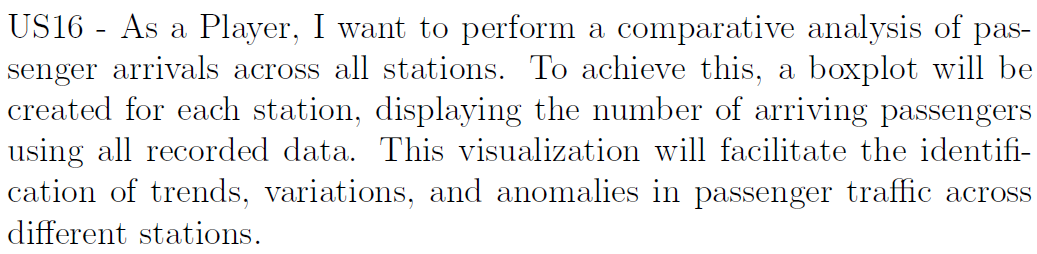

## *User Story Details:*
As a Player, I want to perform a comparative analysis of passenger arrivals across all stations. To achieve this, a boxplot will be created for each station, displaying the number of arriving passengers using all recorded data. This visualization will facilitate the identification of trends, variations, and anomalies in passenger traffic across different stations.

### *Theoretical Explanation*

### What is a boxplot?
A boxplot, also known as a box-and-whisker plot, is a standardized graphical representation of data distribution. It displays the dataset’s minimum, first quartile (Q1), median (Q2), third quartile (Q3), and maximum values. It also highlights potential outliers, providing a clear summary of the central tendency and variability in the data.

### What is the 'median' line in a boxplot?
The line inside the box represents the median of the dataset, which divides the data into two equal halves. It indicates the central value, giving insight into the balance point of the data.

### What do the 'whiskers' represent?
 The whiskers in a boxplot extend to the smallest and largest values within 1.5 times the interquartile range (IQR) from the lower and upper quartiles, respectively. They show the spread of most of the data, excluding outliers.

### What are 'outliers' in a boxplot?
Outliers are data points that fall significantly outside the expected range. In a boxplot, they are plotted as individual dots beyond the whiskers. Outliers may indicate variability, data entry errors, or important anomalies worth investigating.

### What is the 'mean' marker in the boxplot?
If shown, the mean marker (in this case, a white diamond) represents the arithmetic average of the data. It complements the median by giving a sense of the overall balance of all values in the dataset.


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


data = pd.read_csv('Stations_Data.csv', sep=';', decimal=',')

stations = data['Station'].unique()
palette = sns.color_palette("tab10", n_colors=len(stations)) 


sns.set(style="whitegrid")
plt.figure(figsize=(16, 10))  

sns.boxplot(
    x='Year',
    y='Passengers',
    hue='Station',
    data=data,
    palette=palette,
    showmeans=True,
    meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}
)


plt.title('Annual Distribution of Passengers by Station', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Passengers', fontsize=12)


plt.legend(title='Station', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


## US017 - "Analysis of the cargo arriving at each station."

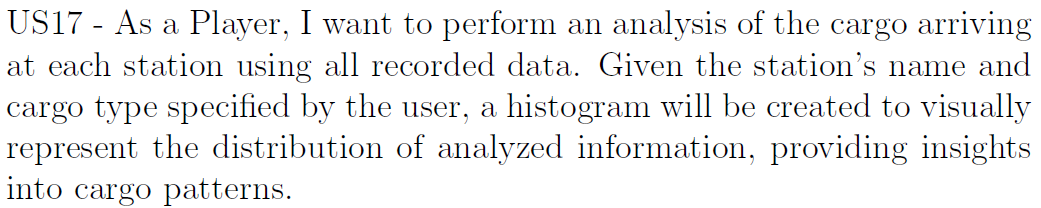

Station name:  Berlin
Cargo type:  Coal


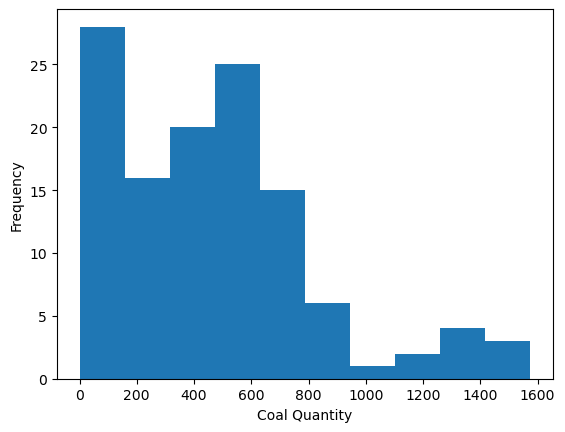

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

filePath = 'Stations_Data.csv'
data = pd.read_csv(filePath, sep=';', decimal=",")

stationName = input('Station name: ')
cargo = input('Cargo type: ')

filteredData = data[data['Station'] == stationName]

if cargo not in data.columns:
    print('Cargo type does not exist')
else:
    cargas = filteredData[cargo]
    plt.xlabel(f"{cargo} Quantity")
    plt.ylabel("Frequency")
    plt.hist(cargas)
    plt.show()


## US018 - "Analysis of train distribution, passengers and mail across different stations

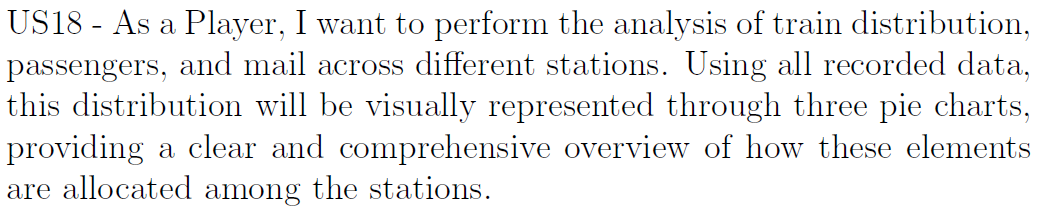

### **Theoretical Concepts**

#### What is a "Pie Chart"?
It's a data representation method, that divides a circle in different sectors which area is proportional to the category frequency each represents.

#### What is "Absolute Frequency"?
It's the number of observations associated to a specific category.

#### What is "Relative Frequency"?
It's the percentage associated to a defined category, considering the total number of observations.

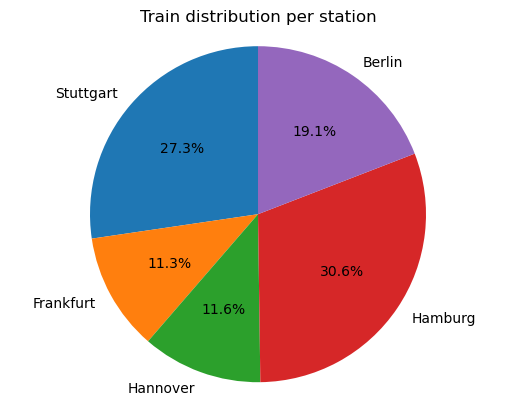

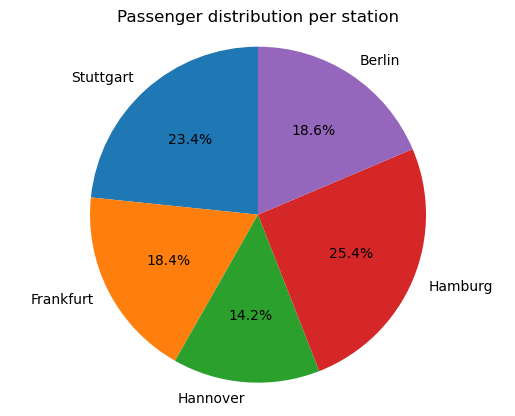

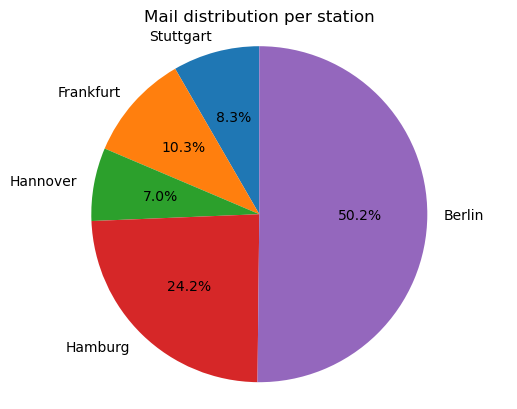

In [2]:
# List of imports
import numpy as np
from scipy import stats
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read of File .csv with the Stations Data
filePath = 'Stations_Data.csv'
stationsData = pd.read_csv(filePath, sep=';', decimal=",")

# Calculating the total data of each attribute
trainsTotal = stationsData['Arrivals'].sum()
passengerTotal = stationsData['Passengers'].sum()
mailTotal = stationsData['Mail'].sum()

# Calculating the data per station
stationsList = stationsData['Station'].unique()

stationNames = []
trainSums = []
passengerSums = []
mailSums = []

for station in stationsList:
    stationRows = stationsData[stationsData['Station'] == station]
    trains = stationRows['Arrivals'].sum()
    passengers = stationRows['Passengers'].sum()
    mail = stationRows['Mail'].sum()

    stationNames.append(station)
    trainSums.append(trains)
    passengerSums.append(passengers)
    mailSums.append(mail)

# Calculating the percentages for each data
trainsPercentageList = []
passengersPercentageList = []
mailPercentageList = []

for i in range(len(stationNames)):
    trainsPercentage = trainSums[i] / trainsTotal
    passengerPercentage = passengerSums[i] / passengerTotal
    mailPercentage = mailSums[i] / mailTotal

    trainsPercentageList.append(trainsPercentage)
    passengersPercentageList.append(passengerPercentage)
    mailPercentageList.append(mailPercentage)

# Displaying a pie chart relative to train distribution
plt.pie(trainsPercentageList, labels=stationNames, autopct='%1.1f%%', startangle=90)
plt.title('Train distribution per station')
plt.axis('equal')
plt.show()

# Displaying a pie chart relative to passenger distribution
plt.pie(passengersPercentageList, labels=stationNames, autopct='%1.1f%%', startangle=90)
plt.title('Passenger distribution per station')
plt.axis('equal')
plt.show()

# Displaying a pie chart relative to mail distribution
plt.pie(mailPercentageList, labels=stationNames, autopct='%1.1f%%', startangle=90)
plt.title('Mail distribution per station')
plt.axis('equal')
plt.show()

### Results interpretation
The results presented on the pie charts allow the player to understand which stations are responsible to deal with an higher quantity of trains, passengers and mail.

These analysis will help to decide which railway lines will need higher attention and maintenance, as well as which stations will need more buildings in order to support the passengers and mail density that arrive there. 

Contribution (in %) of each team member,
| Team Member          | Contribution (%) |
|----------------------|------------------|
| José Cardoso (1241323)      | &#x5B; 25  &#x5D;   |
| Rafael Capão (1241285)      | &#x5B; 25 &#x5D;   |
| João Ferreira (1241166)      | &#x5B; 25 &#x5D;   |
| Iva Silva   (1241176)      | &#x5B; 25 &#x5D;   |

Total: 100 %